# Labor 1 – Gruppe 06
Julius Weber · Jannis Hammerer · Matthis Winter

Auswertung zu 4(a), 5, 6(a), 7, 8, 9 und Funktionsprüfung 10.
Das Notebook vollständig von oben nach unten ausführen. Arbeitsverzeichnis ist der
entpackte Ordner mit diesem Notebook und `lab1.py`. Installation: `pip install -r requirements.txt`.
Alle Abbildungen werden als PDF (für LaTeX) und SVG (Notebook) in `ergebnisse/` geschrieben.

**Datenbasis:** Repository-Stand `6d27ad9cef8c69c1a5f13fc96a5b74782a6ff0dc`.
Die Originaldateien bleiben unverändert. Spaltenreihenfolge ist je Datei explizit festgelegt.
Die Rohwert-Einheit Counts und Messbereiche folgen Dateinamen, Ruhesignalen und
`getX/getY/getZ` des vorhandenen Sketches; die damalige Firmware ist nicht vollständig versioniert.
Bei Aufgabe 6 sind Werte um 1000 daher keine nachgewiesenen mg-Werte.

Die mobile Messung und die zugehörigen Sketches stammen aus dem ergänzten Repository-Stand
`0e878e9c892acd65b4d91fb24b0a2f1dd0da02fe`.


In [1]:
from pathlib import Path
import json
import numpy as np
from lab1 import (AXES, COLORS, load_record, load_mobile, timing, butterworth_lowpass, orientation_table,
                  write_csv, save_plot, accel_panel, plot_timing)

BASE = Path.cwd()
DATA = BASE / 'daten'
RESULT = BASE / 'ergebnisse'
RESULT.mkdir(exist_ok=True)

# Raw counts; Empfindlichkeit = 2048 / Messbereich in g.
a4 = load_record(DATA/'ACC_Data_Aufgabe1.4_2g.12.txt', ('X','Y','Z','t_ms'), 2)
a5slow = load_record(DATA/'ACC_DATA_Aufgabe1.5_4g.12.txt', ('X','Y','Z','t_ms'), 4)
a5fast = load_record(DATA/'ACC_Data_Aufgabe1.5_4g.100.txt', ('t_ms','X','Y','Z'), 4)
a6 = load_record(DATA/'ACC_Data_Aufgabe1.6_2g.12.txt', ('t_ms','X','Y','Z'), 2)
records = [a4, a5slow, a5fast, a6]
inventory = [{'Datei':r.name, 'Messbereich_g':r.full_scale_g, **timing(r)} for r in records]
write_csv(RESULT/'datenpruefung.csv', inventory)
for row in inventory:
    print(f"{row['Datei']}: N={row['N']}, Dauer={row['Dauer_s']:.3f} s, fs_eff={row['fs_eff_Hz']:.4f} Hz")


ACC_Data_Aufgabe1.4_2g.12.txt: N=144, Dauer=11.260 s, fs_eff=12.6998 Hz
ACC_DATA_Aufgabe1.5_4g.12.txt: N=181, Dauer=14.179 s, fs_eff=12.6948 Hz
ACC_Data_Aufgabe1.5_4g.100.txt: N=1217, Dauer=11.982 s, fs_eff=101.4856 Hz
ACC_Data_Aufgabe1.6_2g.12.txt: N=790, Dauer=62.158 s, fs_eff=12.6935 Hz


## 4(a) – Vier Sekunden der ursprünglichen ±2-g-Messung
Gezeigt wird das Fenster 4–8 s relativ zum ersten Messwert. Damit wird die ruhige
Anfangsphase nicht zum überwiegenden Teil des Ausschnitts. Division durch **1024 Counts/g**.


X: Min=-1.8320 g, Max=1.3389 g, Grenzcodes=0
Y: Min=-2.0000 g, Max=1.9990 g, Grenzcodes=37
Z: Min=-0.8486 g, Max=1.6914 g, Grenzcodes=0


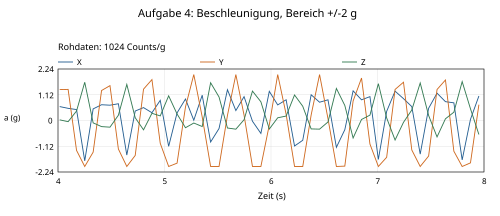

In [2]:
fig4 = save_plot(RESULT/'aufgabe4', 'Aufgabe 4: Beschleunigung, Bereich +/-2 g',
                 [accel_panel(a4, 'Rohdaten: 1024 Counts/g', 4, 8)])
for j,a in enumerate(AXES):
    n = int(np.count_nonzero((a4.raw[:,j] == -2048) | (a4.raw[:,j] == 2047)))
    print(f'{a}: Min={a4.g[:,j].min():.4f} g, Max={a4.g[:,j].max():.4f} g, Grenzcodes={n}')
fig4


## 5 – Messbereich und zeitliche Auflösung vergleichen
Verglichen werden die Aufnahmen mit ±2 g bei 12,70 Hz und ±4 g bei 101,49 Hz.
Der größere Messbereich und die höhere Datenrate ändern sich gleichzeitig. Die Bewegungen wurden separat aufgenommen.
±4 g: **512 Counts/g**, nicht 500 Counts/g.
Das Datenblatt (Rev. 10, S. 23) nennt `XYZ_DATA_CFG` (0x0E), `FS[1:0]`:
00 → ±2 g, 01 → ±4 g, 10 → ±8 g, 11 → reserviert.
`CTRL_REG1` (0x2A), `DR[2:0]` (S. 40–41):
000/001/010/011/100/101/110/111 → 800/400/200/100/50/12,5/6,25/1,56 Hz.
Der abgegebene Sketch setzt ±4 g und 100 Hz als reproduzierbare neue Konfiguration.
Die im alten Sketch eingestellten 200 Hz beweisen nicht die Einstellung früherer Aufnahmen.


ACC_DATA_Aufgabe1.5_4g.12.txt max |a| = 3.7852 g
ACC_Data_Aufgabe1.5_4g.100.txt max |a| = 4.0 g


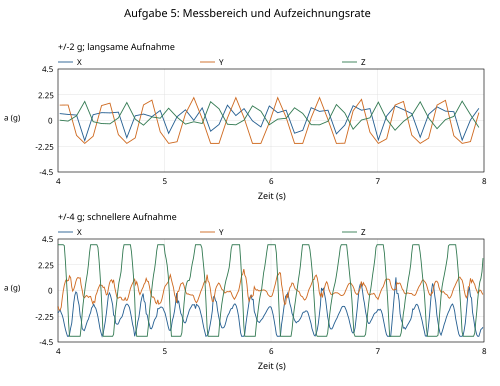

In [3]:
panels = [accel_panel(a4, '+/-2 g; langsame Aufnahme', 4, 8),
          accel_panel(a5fast, '+/-4 g; schnellere Aufnahme', 4, 8)]
# Gleiche y-Skala ermöglicht direkten Amplitudenvergleich.
for p in panels: p['ylim'] = (-4.5, 4.5)
fig5 = save_plot(RESULT/'aufgabe5', 'Aufgabe 5: Messbereich und Aufzeichnungsrate', panels)
for r in (a5slow,a5fast):
    print(r.name, 'max |a| =', round(float(np.abs(r.g).max()),4), 'g')
fig5


## 6(a,b) – Eine zusammenhängende Aufnahme mit sechs Orientierungen
Alle Originalmesswerte einschließlich Drehphasen werden gemeinsam dargestellt.
Die Statistik nutzt explizite ruhige Innenfenster, keine neu zusammengesetzten Messungen.


Z-, 1–9 s: X=-0.0102 g, Y=-0.0231 g, Z=-0.9700 g
Z+, 12–19 s: X=-0.0046 g, Y=-0.0174 g, Z=+1.0278 g
Y-, 22–29 s: X=-0.0116 g, Y=-1.0080 g, Z=+0.0205 g
Y+, 33–39 s: X=+0.0047 g, Y=+1.0200 g, Z=+0.0178 g
X-, 42–49 s: X=-1.0284 g, Y=-0.0469 g, Z=+0.0380 g
X+, 53–61 s: X=+1.0289 g, Y=-0.0063 g, Z=-0.0106 g


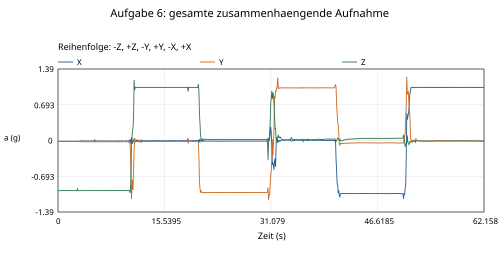

In [4]:
fig6 = save_plot(RESULT/'aufgabe6', 'Aufgabe 6: gesamte zusammenhaengende Aufnahme',
                 [accel_panel(a6, 'Reihenfolge: -Z, +Z, -Y, +Y, -X, +X')], panel_height=210)
orientations = orientation_table(a6)
write_csv(RESULT/'orientierungen.csv', orientations)
for row in orientations:
    means = ', '.join(f'{a}={row[a+"_Mittel_g"]:+.4f} g' for a in AXES)
    print(f"{row['Lage']}, {row['Start_s']}–{row['Ende_s']} s: {means}")
fig6


## 7 – Gefilterte und ungefilterte Daten
Butterworth-Tiefpass vierter Ordnung mit 0,5 Hz Grenzfrequenz.
Vorwärts und rückwärts angewendet (Zero Phase), um schnelle Schwankungen
zu dämpfen und die stationären Lagewerte zu erhalten. Die Bezeichnung
„Bandpass“ in der Vorlage wurde an die dort tatsächlich verwendete Einstellung
lowpass angepasst. Die Grenzfrequenz stammt aus der bisherigen Git-Auswertung.


Effektive Abtastrate: 12.6935 Hz


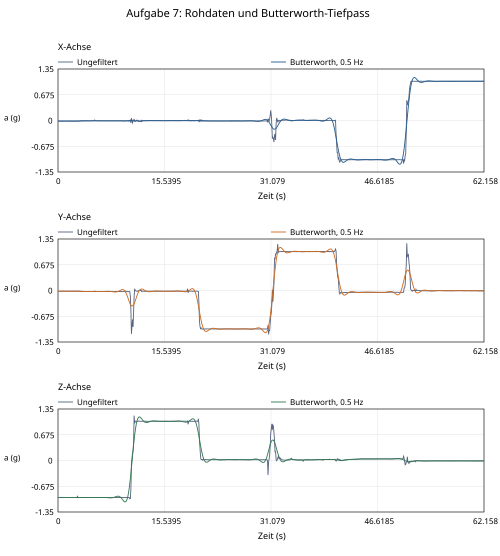

In [5]:
cutoff_hz = 0.5
filter_order = 4
fs = timing(a6)["fs_eff_Hz"]
filtered = butterworth_lowpass(a6.g, cutoff_hz, fs, filter_order)
panels = []
for j,a in enumerate(AXES):
    panels.append({'title':a+'-Achse', 'xlim':(0,a6.t[-1]), 'ylim':(-1.35,1.35), 'ylabel':'a (g)',
                   'curves':[(a6.t,a6.g[:,j],'Ungefiltert','#586580',None),
                             (a6.t,filtered[:,j],'Butterworth, 0.5 Hz',COLORS[j],None)]})
fig7 = save_plot(RESULT/'aufgabe7', 'Aufgabe 7: Rohdaten und Butterworth-Tiefpass', panels)
print(f"Effektive Abtastrate: {fs:.4f} Hz")
fig7


## 8 – Abtastfrequenz: Mittelwert und Abweichung
Aus den **auf dem Mikrocontroller erzeugten Millisekunden-Zeitstempeln**:

Δtᵢ = (tᵢ₊₁ − tᵢ) / 1000; fᵢ = 1 / Δtᵢ.

Berichtet werden arithmetischer Mittelwert und **Stichproben-Standardabweichung**
der fᵢ (ddof=1). Zusätzlich: effektive Rate f_eff = (N−1)/(t_letzter−t_erster)
= 1/Mittelwert(Δt), die nicht exakt Mittelwert(1/Δt) entspricht.
Die Intervalle sind durch `millis()` auf 1 ms quantisiert; die Streuung beschreibt
gespeicherte Intervalle einschließlich dieser Quantisierung, nicht allein Sensorjitter.
Die Herkunft der Zeitspalte wird durch den Sketch gestützt; der damalige Sketch-Stand
ist nicht für jede Datei gesichert. Seriellen Konsolenzeitstempeln werden keine Daten entnommen.


N: 790.000000
Dauer_s: 62.158000
dt_Mittel_ms: 78.780735
dt_SD_ms: 0.529662
fs_eff_Hz: 12.693459
fi_Mittel_Hz: 12.694035
fi_SD_Hz: 0.085899
dt_Min_ms: 77.000000
dt_Max_ms: 80.000000


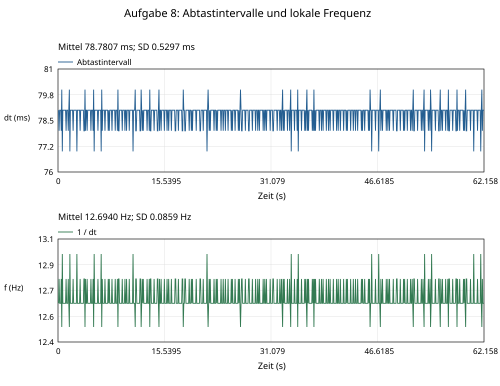

In [6]:
stats6 = timing(a6)
for key,value in stats6.items(): print(f'{key}: {value:.6f}')
write_csv(RESULT/'abtastfrequenz.csv', [{'Messung':'stationaer', **stats6}])
fig8 = plot_timing(a6, RESULT/'aufgabe8', 'Aufgabe 8: Abtastintervalle und lokale Frequenz')
fig8


## 9 – Mobile Messung
Lab1Code2 speichert X, Y, Z bereits in g (±8 g, Division durch 256) und MCU-Zeit in ms.
Die Originaldatei enthält drei Abschnitte mit steigender Zeit. Verwendet werden die ersten
zehn Sekunden des letzten Abschnitts. Zeitdifferenzen über Neustarts hinweg entfallen.
Die eingestellte Sensor-ODR beträgt 200 Hz. Der Sketch führt je Zeile einen Append-Aufruf,
mehrere I²C-Schreiboperationen und drei Sensorabfragen aus.


Abschnittsstarts (Datenzeilen): [  1 375 405]
stationaer: {'N': 790, 'Dauer_s': 62.158, 'dt_Mittel_ms': 78.78073510773129, 'dt_SD_ms': 0.5296622494805221, 'fs_eff_Hz': 12.693458605489237, 'fi_Mittel_Hz': 12.694035360926634, 'fi_SD_Hz': 0.08589918940422012, 'dt_Min_ms': 77.0, 'dt_Max_ms': 80.0}
mobil: {'N': 536, 'Dauer_s': 9.985, 'dt_Mittel_ms': 18.663551401869157, 'dt_SD_ms': 0.8925820521000734, 'fs_eff_Hz': 53.58037055583375, 'fi_Mittel_Hz': 53.69780506349056, 'fi_SD_Hz': 2.4678598287294333, 'dt_Min_ms': 16.0, 'dt_Max_ms': 23.0}
Differenz fs_eff: +40.8869 Hz


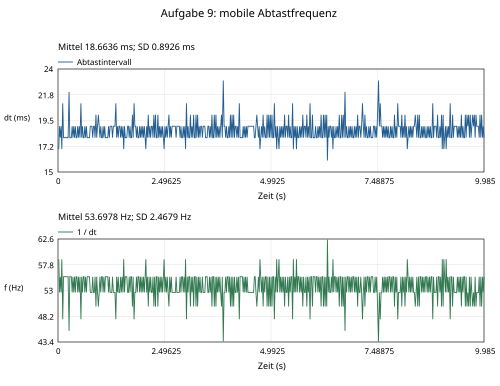

In [7]:
mobile, segment_starts = load_mobile(DATA/'ACC_Data_Aufgabe1.9_8g.200.txt')
stats9 = timing(mobile)
write_csv(RESULT/'vergleich_mobil.csv', [
    {'Messung':'stationaer', **stats6}, {'Messung':'mobil', **stats9}])
print('Abschnittsstarts (Datenzeilen):', segment_starts)
print('stationaer:', stats6)
print('mobil:', stats9)
print(f"Differenz fs_eff: {stats9['fs_eff_Hz']-stats6['fs_eff_Hz']:+.4f} Hz")
fig9 = plot_timing(mobile, RESULT/'aufgabe9', 'Aufgabe 9: mobile Abtastfrequenz')
fig9


## 10 – Reproduzierbarkeit und Grenzen
Die folgenden Prüfungen kontrollieren Zeitfolge, Einheiten, Filterform und geforderte Exporte.
Die Messdaten zu 4–6 werden nicht nachträglich als andere Versuche ausgegeben.
Die mobile Auswertung verwendet ausschließlich eine zusammenhängende Zeitfolge.


In [8]:
assert all(np.all(np.diff(r.t_ms)>0) for r in records)
assert np.isclose(a6.ms2[0,2], a6.raw[0,2]/1024*9.80665)
assert filtered.shape == a6.g.shape and np.isfinite(filtered).all()
assert len(orientations) == 6
assert len({r['Lage'] for r in orientations}) == 6
assert 9.95 <= mobile.t[-1] <= 10 and np.all(np.diff(mobile.t_ms)>0)
assert all((RESULT/f'aufgabe{k}.pdf').exists() for k in (4,5,6,7,8,9))
summary = {'Gruppe':'06', 'Repository_Commit':'6d27ad9cef8c69c1a5f13fc96a5b74782a6ff0dc',
           'Daten':inventory, 'Orientierungen':orientations, 'Aufgabe8':stats6,
           'Aufgabe9':stats9}
(RESULT/'auswertung.json').write_text(json.dumps(summary,ensure_ascii=False,indent=2),encoding='utf-8')
print('Pruefungen 4–9 bestanden.')


Pruefungen 4–9 bestanden.
